# Fine-tune PILOT for field extraction on FATURA

This notebook turns invoice images into an ordered sequence of six annotated fields.
We restore pretrained weights before
adding schema tokens, audit target lengths, compute RGB statistics on training pixels only,
apply prompt-masked teacher forcing, and export a model/tokenizer bundle.

Configuration, metrics and checkpoints are local files.

**Before starting**, apply the public training patch and this notebook update, install the
notebook dependencies in your kernel environment, and download the released PILOT weights/tokenizer:

~~~bash
pip install -e ".[notebooks]"
jupyter lab
~~~

The GPU run is intended for you to execute. A small CPU run only checks the code path;
the sample limits below are a tutorial subset, not a published benchmark.

**Example settings, not tuned hyperparameters.** These notebooks illustrate a workflow; image
resolution, crop height, learning rate, noise, effective batch size, sequence limit and epoch count
have not been optimized for this dataset. Compare settings on validation and reserve test for final
evaluation. The small default subsets check execution and do not establish model quality.

A few hundred training examples are generally insufficient for robust adaptation: the model may
memorize examples, generate unstable outputs or fail on new layouts and text. Several thousand
diverse labeled examples are often a more useful starting point, but there is no universal sample
threshold or guarantee; annotation quality, task complexity and similarity to pretraining matter.
Use learning curves to decide whether more data are needed. Synthetic data can broaden coverage,
provided they match the intended domain; evaluate on separate, representative real documents.

**Resolution affects recognition.** Excessive downscaling can remove strokes and make characters
indistinguishable; later upscaling cannot recover that information. Inspect the actual prepared images,
especially small text. Higher resolution increases encoder cost, memory and visual sequence length.
Keep the same resize/crop/padding/normalization policy at inference and tune this tradeoff on validation.

## 0. Setup

In [1]:
from pathlib import Path
import gc
import json
import sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pilot").is_dir() and (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise RuntimeError("Place this notebook inside the PILOT repository and launch Jupyter from that repository.")
sys.path.insert(0, str(ROOT))


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from IPython.display import display
import torch

from examples.finetuning.common import audit_targets, experiment_model_config, read_jsonl, save_json
from examples.finetuning.evaluation import history_table, load_best, predict_records
from pilot.training.trainer import train

print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())


Python: c:\Users\hamdi\OneDrive\Desktop\python_projetcs\PILOT\.venv\Scripts\python.exe
PyTorch: 2.15.0+cpu | CUDA: False


In [3]:
from examples.finetuning.fatura import FIELDS, SPECIAL_TOKENS, TASK_PROMPT, download_fatura, prepare_fatura
from examples.finetuning.evaluation import field_metrics, parse_fields


In [4]:
DATA_DIR = ROOT / "data" / "fatura"
ARCHIVE_PATH = DATA_DIR / "raw" / "FATURA2.zip"
PREPARED_DIR = DATA_DIR / "prepared_example"
EXPERIMENT_DIR = ROOT / "runs" / "fatura_example"
MODEL_CONFIG = ROOT / "configs" / "pilot_generic.json"
LIMITS = {"train": 400, "validation": 80, "test": 80}
MAX_SIDE = 1280
EPOCHS = 10
EXTRA_TOKENS = SPECIAL_TOKENS
SELECTION_METRIC = "field_micro_f1"
METRIC_FIELDS = list(FIELDS)


## 1. Prepare data once

Source: [FATURA2, Zenodo record 10371464](https://zenodo.org/records/10371464),
released under CC BY 4.0. The first run downloads the official archive (~691 MB)
and verifies its published MD5 checksum. Subsequent runs reuse it.

We use the authors' **strategy 1 CSV splits** and **white-background images only**.
Different instances of the same template can occur in train, validation and test:
this tests new invoice content on familiar layouts. The colored image of the same invoice
is not added as another sample, so it cannot cross splits.
For unseen-layout generalization, create a separate experiment split by template ID.
Subsampling is balanced across templates rather than taking the first CSV rows.

In [5]:
archive = download_fatura(ARCHIVE_PATH)
prepared = prepare_fatura(archive, PREPARED_DIR, limits=LIMITS, max_side=MAX_SIDE, seed=42)
display(pd.DataFrame({"examples": prepared["counts"], "source_documents": prepared["source_counts"]}))


Reuse prepared data: c:\Users\hamdi\OneDrive\Desktop\python_projetcs\PILOT\data\fatura\prepared_example


,examples,source_documents
train,400,400
validation,80,80
test,80,80


### Define what the model should extract

We use `Original_Format` annotations instead of trying to infer semantic fields from BIO labels.
Each field keeps **the complete annotated region text**, including any printed field label,
date format and currency. For example, a total may be `TOTAL : 870.74 USD` rather than just
`870.74`. Whitespace is normalized; no amount/date parsing or arithmetic correction is applied.
This avoids inventing ground truth that the source does not provide.

Every field has paired tags in a fixed order. Missing fields have an empty tag pair.
`<sep/>` separates repeated values.

,target_field,source_key
0,invoice_number,NUMBER
1,invoice_date,DATE
2,due_date,DUE_DATE
3,subtotal,SUB_TOTAL
4,tax,TAX
5,total,TOTAL


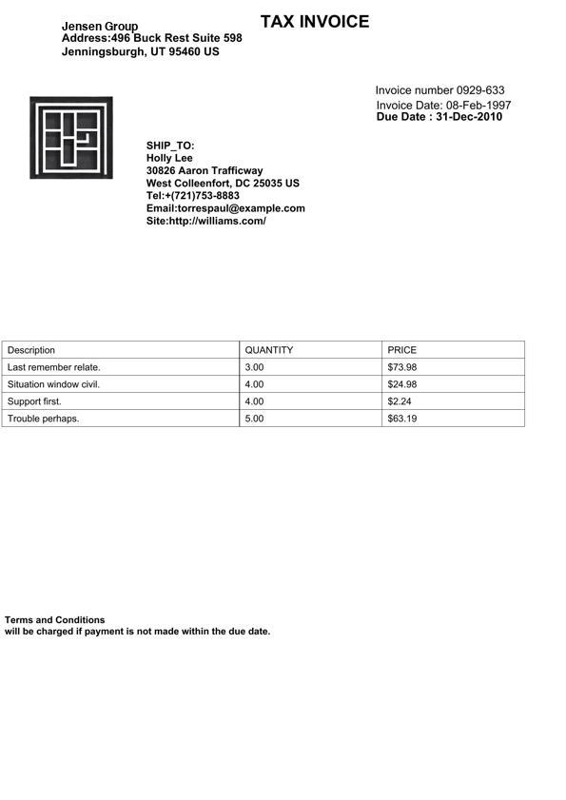

Prompt: <invoice_extract>
Target: <invoice_number>Invoice number 0929-633</invoice_number><invoice_date>Invoice Date: 08-Feb-1997</invoice_date><due_date>Due Date : 31-Dec-2010</due_date><subtotal></subtotal><tax></tax><total></total>


invoice_number      [Invoice number 0929-633]
invoice_date      [Invoice Date: 08-Feb-1997]
due_date             [Due Date : 31-Dec-2010]
subtotal                                   []
tax                                        []
total                                      []
dtype: object

Fraction of documents with a nonempty source annotation:


,train,validation,test
invoice_number,0.88,0.8875,0.8875
invoice_date,0.98,0.9750,0.9750
due_date,0.58,0.5750,0.5750
subtotal,0.68,0.6750,0.6750
tax,0.38,0.4000,0.4000
total,0.80,0.7750,0.7750


In [6]:
display(pd.DataFrame([{"target_field": key, "source_key": value} for key, value in FIELDS.items()]))
sample = read_jsonl(PREPARED_DIR / "train.jsonl")[0]
with Image.open(PREPARED_DIR / sample["image"]) as image:
    preview = image.copy()
preview.thumbnail((600, 800))
display(preview)
print("Prompt:", sample["prompt"])
print("Target:", sample["target"])
display(pd.Series(sample["fields"]))
presence = {}
for split in LIMITS:
    rows = read_jsonl(PREPARED_DIR / f"{split}.jsonl")
    presence[split] = {name: sum(bool(row["fields"][name]) for row in rows) / len(rows) for name in FIELDS}
print("Fraction of documents with a nonempty source annotation:")
display(pd.DataFrame(presence))


Prepared PNGs, JSONL manifests, split provenance and train-only image statistics are saved in
`PREPARED_DIR`. You can restart the kernel and skip the download/preparation cell after loading:

~~~python
prepared = json.loads((PREPARED_DIR / "prepared.json").read_text())
~~~

A normal rerun also reuses the prepared files. If you change limits, image size or field definitions,
choose a new `PREPARED_DIR` so cached images and targets cannot silently diverge.

## 2. Audit and train

The copied model config keeps the base checkpoint's architecture and absolute artifact paths,
while replacing preprocessing statistics with those of the prepared training images.
The audit tokenizer adds the same ordered tokens that the model loader will add **after** strict
checkpoint loading. The maximum training sequence length is computed from train and validation;
decoder positional embeddings are not rebuilt or shortened.

In [17]:
model_config_path = experiment_model_config(MODEL_CONFIG, EXPERIMENT_DIR / "config" / "model.json", prepared["image_stats"])
length_summary, max_length = audit_targets(PREPARED_DIR, model_config_path, EXTRA_TOKENS)
display(pd.DataFrame(length_summary))
print("Dataset max_length:", max_length)
print("Decoder positional capacity is unchanged.")


Audit train targets:   0%|          | 0/400 [00:00<?, ?it/s]

Audit validation targets:   0%|          | 0/80 [00:00<?, ?it/s]

,split,examples,max_tokens,median_tokens
0,train,400,78,56.0
1,validation,80,73,56.0


Dataset max_length: 96
Decoder positional capacity is unchanged.


Use one image per microbatch and accumulation for an effective batch of four.
Lexical noise replaces tokens with other lexical tokens from the same sequence; prompts,
field tags, BOS/EOS/PAD and clean targets are protected. Compare a noise rate of 0.00 and 0.05
on validation when doing a real experiment.

The best checkpoint maximizes **generated validation field micro F1**, using the ordered
`METRIC_FIELDS` schema and the same matching policy as final evaluation. No validation loss is computed.
CUDA precision is chosen automatically; CPU uses FP32.

Training uses a simple cross-entropy averaged over supervised target tokens, including structural
tokens and EOS; prompt and padding positions are masked. Frequent or long token categories can
dominate that average. A more elaborate objective could balance lexical, field-tag, coordinate,
separator and EOS contributions or normalize separate loss terms. The categories, weights and any
benefit are dataset-dependent: this example leaves them unweighted and makes no optimality claim.
Evaluate changes using generated CER or field F1, not training loss alone.

In [18]:
RUN_DIR = EXPERIMENT_DIR / "training"
training_config = {
    "model_config": str(model_config_path),
    "train_manifest": str(PREPARED_DIR / "train.jsonl"),
    "validation_manifest": str(PREPARED_DIR / "validation.jsonl"),
    "output_dir": str(RUN_DIR),
    "extra_tokens": EXTRA_TOKENS,
    "epochs": EPOCHS,
    "learning_rate": 1e-5,
    "batch_size": 1,
    "accumulation_steps": 4,
    "max_length": max_length,
    "num_workers": 0,
    "precision": "auto",
    "gradient_checkpointing": False,
    "noise_rate": 0.05,
    "noise_strategy": "sequence",
    "selection_metric": SELECTION_METRIC,
    "metric_fields": METRIC_FIELDS,
    "seed": 42,
}
CONFIG_PATH = EXPERIMENT_DIR / "config" / "training.json"
save_json(CONFIG_PATH, training_config)
display(pd.Series(training_config))


model_config              c:\Users\hamdi\OneDrive\Desktop\python_projetc...
train_manifest            c:\Users\hamdi\OneDrive\Desktop\python_projetc...
validation_manifest       c:\Users\hamdi\OneDrive\Desktop\python_projetc...
output_dir                c:\Users\hamdi\OneDrive\Desktop\python_projetc...
extra_tokens              [<invoice_extract>, <sep/>, <invoice_number>, ...
epochs                                                                   10
learning_rate                                                       0.00001
batch_size                                                                1
accumulation_steps                                                        4
max_length                                                               96
num_workers                                                               0
precision                                                              auto
gradient_checkpointing                                                False
noise_rate  

### Run or resume

The next cell resumes from `last.pt` when present. Keep the same settings and epoch budget
when resuming. To change them, choose another `EXPERIMENT_DIR`.
Training uses only train/validation. The test set is first used after checkpoint selection.

In [19]:
resume = (RUN_DIR / "last.pt").is_file()
result = train(CONFIG_PATH, resume=resume)
print(result)


Check train.jsonl:   0%|          | 0/400 [00:00<?, ?it/s]

Check validation.jsonl:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch 1/10


Train:   0%|          | 0/400 [00:00<?, ?it/s]

KeyboardInterrupt: 

### Inspect local training history

In [ ]:
history = history_table(RUN_DIR)
display(history)
history.plot(x="epoch", y="train_loss", marker="o", ylabel="Training token cross-entropy", grid=True)
plt.show()
history.plot(x="epoch", y=f"validation.{SELECTION_METRIC}", marker="o", ylabel=SELECTION_METRIC, grid=True)
plt.show()


## 3. Reload the best checkpoint and predict

Reloading the exported tokenizer is essential: the base tokenizer does not know the added tags.
Predictions use the same prepared image pixels and normalization as training.

In [ ]:
model = None
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
model, tokenizer, inference_config = load_best(RUN_DIR / "best" / "config.json")
predictions = predict_records(model, tokenizer, inference_config, PREPARED_DIR / "test.jsonl", max_length=max_length, limit=None)
save_json(RUN_DIR / "test_predictions.json", predictions)
print("Test examples:", len(predictions))
print("EOS termination rate:", sum(p["terminated"] for p in predictions) / len(predictions))


In [ ]:
scores, per_field = field_metrics(predictions, list(FIELDS))
display(pd.Series(scores))
display(pd.DataFrame(per_field))
save_json(RUN_DIR / "test_metrics.json", {"summary": scores, "per_field": per_field})


Field precision/recall/F1 use one-to-one multiset matching after Unicode, whitespace and case
normalization. Repeated values count separately. Labels, punctuation, currencies and amount/date
formats remain part of each value. `parse_valid_rate` additionally checks the ordered tag grammar.
`document_exact_match` requires all normalized field multisets and the grammar to match.
An EOS rate below 1 indicates predictions that hit the generation cap.

In [ ]:
example = predictions[0]
predicted_fields, valid_parse = parse_fields(example["prediction"], list(FIELDS))
gold_fields, _ = parse_fields(example["target"], list(FIELDS))
with Image.open(PREPARED_DIR / example["image"]) as image:
    preview = image.copy()
preview.thumbnail((600, 800))
display(preview)
display(pd.DataFrame({"ground_truth": gold_fields, "prediction": predicted_fields}))
print("Valid parse:", valid_parse)
print("Raw prediction:", example["prediction"])


### Predict a new invoice

This helper applies the same RGB/resize/padding preparation and reuses a content-addressed cache.

In [ ]:
CUSTOM_PROMPT = TASK_PROMPT
CUSTOM_HEIGHT = None

def predict_image(image_path):
    from hashlib import sha256
    from examples.finetuning.common import save_rgb
    image_path = Path(image_path)
    fingerprint = sha256(image_path.read_bytes()).hexdigest()[:12]
    prepared_image = EXPERIMENT_DIR / "custom" / f"{image_path.stem}_{fingerprint}.png"
    if not prepared_image.exists():
        with Image.open(image_path) as image:
            save_rgb(image, prepared_image, max_side=MAX_SIDE, target_height=CUSTOM_HEIGHT)
    manifest = EXPERIMENT_DIR / "custom" / "example.jsonl"
    manifest.write_text(json.dumps({"image": prepared_image.name, "prompt": CUSTOM_PROMPT, "target": ""}) + "\n")
    return predict_records(model, tokenizer, inference_config, manifest, max_length=max_length, limit=1)[0]["prediction"]

# prediction = predict_image("/path/to/your/image.png")
# print(prediction)


## 4. CPU inference after training

CPU cost can be reduced through several complementary optimizations: per-channel GroupNorm
(already used by this implementation), separate self/cross-attention KV caches, channels-last encoder
layout, cached positional encodings, CPU thread tuning, and optional encoder compilation.
Combined optimizations can sometimes make inference **around 3× faster**, but this is an indicative
possibility, not a measured result or a guarantee for this notebook. Hardware, software versions,
image resolution and generated length determine the gain; some settings can be slower.

The short example below measures a baseline and an optimized run with identical inputs, decoding
settings and CPU thread count. It compares token IDs as well as latency. One example is only a local
sanity check: benchmark representative sizes and outputs, report startup separately, and recompute
CER/F1 on a held-out set before deployment. Small floating-point differences can change generation.
The benchmark uses validation images without consulting their labels and excludes disk I/O.

Compilation is optional and disabled by default. Set `COMPILE_ENCODER=True` to try
`torch.compile` on a machine with a supported compiler; its first call can take minutes and new
shapes may trigger additional compilation. Warm-up is excluded from the displayed latency.
The helper restores the eager encoder if benchmarking fails and surfaces the error.
Quantization, batching and alternative inference engines are additional experiments; recheck quality.

Only the original **`best/model.pt`**, its config and tokenizer are saved. Apply runtime optimizations
after loading these artifacts; do not export a compiled module as the training checkpoint.
See the [performance guide](../docs/performance.md) for scope and upstream references.

In [ ]:
from examples.finetuning.cpu import available_cpus, benchmark_cpu

CPU_THREADS = min(4, available_cpus())
COMPILE_ENCODER = False
CPU_EXAMPLES = 1
CPU_REPEATS = 3
cpu_report = benchmark_cpu(
    model, tokenizer, inference_config, PREPARED_DIR / "validation.jsonl",
    max_length=max_length, num_threads=CPU_THREADS, compile_encoder=COMPILE_ENCODER,
    examples=CPU_EXAMPLES, repeats=CPU_REPEATS,
)
display(pd.DataFrame(cpu_report["per_example"]))
print(f"Measured speedup: {cpu_report['speedup']:.2f}x | Identical token IDs: {cpu_report['same_token_ids']}")
if not cpu_report["same_token_ids"]:
    print("Outputs differ: recompute CER/F1 before interpreting this as an equivalent-quality speedup.")
save_json(RUN_DIR / "cpu_benchmark.json", cpu_report)
torch.set_num_threads(CPU_THREADS)


## What to adapt for your own dataset

Replace the source adapter, define your field keys/tags and create the same JSONL manifests.
Keep splits separated by source document and inspect the actual target strings before training.
Add task-specific value normalization only when your annotation contract explicitly requires it.

Citation: Mahmoud Limam, Marwa Dhiaf and Yousri Kessentini,
*FATURA: A Multi-Layout Invoice Image Dataset for Document Analysis and Understanding* (2023).